# Homework 5 训练CNN的额外组件：初始化、归一化与数据增强 —— 猫狗分类

Author: Lianjie (Marc) Shi  
要求：本周学习了训练卷积神经网络的额外组件：初始化、归一化与数据增强。初始化防止神经网络"出师未捷身先死"，归一化在训练中规范网络中间产物的尺度，数据增强通过对图像进行变换创造更多的【同义】样本，客观上等效增加训练样本、提升泛化能力。本周作业使用PyTorch实现基于猫狗数据集的分类任务（数据读取 — 模型搭建 — 训练 — 推断），并比较四种搭建方法的效果：(1) 没有BN和DA (2) 只有BN (3) 只有DA (4) BN和DA均使用。具体要求：

- 【1】代码应包含完整的流程（50分），包括数据读取（数据集构造、生成器、数据展示）；模型搭建（定义模型类，实例化后展示模型summary）；模型训练（定义损失函数，优化器，监控指标，进行训练）；模型推断（从测试集取出5张图片进行分类，输出预测结果和概率）；
- 【2】代码应进行注释，同时请分析自己搭建的CNN的参数数目（10分）；
- 【3】假设训练完成后模型在测试集上的分类精度为 x%，模型精度得分为 (20*x/100)；
- 【4】利用训练好的模型进行预测（10分），报告的美观程度 (10分)；
- 【5】请提交【PDF】版本的作业（非PDF版本扣10分）：先将包含代码和运行结果的.ipynb文件输出为html文件，再将html文件通过【打印】输出为【PDF】格式。

## 0. 导入与随机种子

固定 random / numpy / torch / CUDA 的全部随机种子，保证初始权重、数据打乱顺序每次都相同，结果完全可复现。

In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torchvision.utils import make_grid
from PIL import Image
import matplotlib.pyplot as plt


def set_seed(seed=1):
    """固定全部随机种子，保证结果可复现。"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(1)  # 随机种子：不改这里，每次运行的结果就一样

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")
print(f"PyTorch 版本: {torch.__version__}")

# ===== 全局超参数 =====
IMSIZE = 128  # 输入图片尺寸（与课件一致）

data_dir = '/Pytorch_Book_ZhouRUC/dataset/CatDog'
batch_size = 128
epochs = 30    # 与课件训练曲线一致
lr = 1e-3

class_names = ['cat', 'dog']  # ImageFolder 按字母序: cats->0, dogs->1

使用设备: cuda
PyTorch 版本: 1.8.1+cu111


## 1. 数据读取

### 1.1 数据集介绍与目录结构

猫狗数据集来自2013年Kaggle竞赛（dogs-vs-cats），核心任务是对猫和狗进行二分类。样本量：**15000张训练、10000张验证，猫狗各50%**。训练集和验证集已经按规范化格式存储：根目录下分为 `train/` 与 `validation/`，每个目录下再按类别分为 `cats/` 与 `dogs/`。由于目录本身就是标签，可以直接使用 `torchvision.datasets.ImageFolder` 一步读成 Dataset（课堂介绍的第三种定义Dataset的方式）。

In [2]:
# 展示目录结构并统计各类别图片数量
print("目录结构: CatDog/{train, validation}/{cats, dogs}")
for split in ['train', 'validation']:
    for cls in ['cats', 'dogs']:
        d = os.path.join(data_dir, split, cls)
        n = len(os.listdir(d))
        print(f"{split}/{cls}: {n} 张")

目录结构: CatDog/{train, validation}/{cats, dogs}
train/cats: 7500 张
train/dogs: 7500 张
validation/cats: 5000 张
validation/dogs: 5000 张


### 1.2 定义数据变换（数据增强 DA 与非增强两套）

- **不使用DA**：只做 `Resize` + `ToTensor`，作为基线；
- **使用DA**：在缩放后增加 `RandomCrop(带填充)` 与 `RandomHorizontalFlip`。裁剪和平移、翻转都不改变图像语义（猫还是猫），但能制造新的"同义"样本，等效扩充训练集；
- **验证集永远不做增强**，只用于评估。

In [3]:
# 不使用数据增强：只做尺寸缩放和张量化
transform_no_da = transforms.Compose([
    transforms.Resize((IMSIZE, IMSIZE)),  # Resize成规定尺寸
    transforms.ToTensor(),                # 转为 [0,1] 的 tensor
])

# 使用数据增强(DA)：随机裁剪 + 随机水平翻转，制造"同义"样本
transform_da = transforms.Compose([
    transforms.Resize((IMSIZE, IMSIZE)),      # Resize成规定尺寸
    transforms.RandomCrop(IMSIZE, padding=8), # 随机裁剪（带填充，等效小幅度平移）
    transforms.RandomHorizontalFlip(),        # 随机水平翻转
    transforms.ToTensor(),
])

# 验证集变换：任何配置下都不做增强
transform_val = transforms.Compose([
    transforms.Resize((IMSIZE, IMSIZE)),
    transforms.ToTensor(),
])

### 1.3 构造数据集与数据生成器（DataLoader）

In [4]:
def build_loaders(use_da):
    """根据是否使用数据增强，构建训练/验证 DataLoader。

    参数:
        use_da: True 表示训练集使用数据增强，False 表示不用
    返回:
        train_set, val_set, train_loader, val_loader
    """
    train_tf = transform_da if use_da else transform_no_da
    # ImageFolder 自动把 "目录名" 当作类别标签
    train_set = torchvision.datasets.ImageFolder(
        root=os.path.join(data_dir, 'train'), transform=train_tf)
    val_set = torchvision.datasets.ImageFolder(
        root=os.path.join(data_dir, 'validation'), transform=transform_val)
    # 固定 generator 种子，保证每个 epoch 的 batch 打乱顺序可复现
    g = torch.Generator()
    g.manual_seed(1)
    train_loader = torch.utils.data.DataLoader(
        train_set, batch_size=batch_size, shuffle=True,
        num_workers=2, pin_memory=True, generator=g)
    val_loader = torch.utils.data.DataLoader(
        val_set, batch_size=batch_size, shuffle=False,
        num_workers=2, pin_memory=True)
    return train_set, val_set, train_loader, val_loader


train_set, val_set, train_loader, val_loader = build_loaders(use_da=True)
print(f"训练集大小: {len(train_set)}  验证集大小: {len(val_set)}")
print(f"类别映射: {train_set.class_to_idx}")  # {'cats': 0, 'dogs': 1}

训练集大小: 15000  验证集大小: 10000
类别映射: {'cats': 0, 'dogs': 1}


### 1.4 数据展示

图片张量形状: torch.Size([128, 3, 128, 128])
标签张量形状: torch.Size([128])


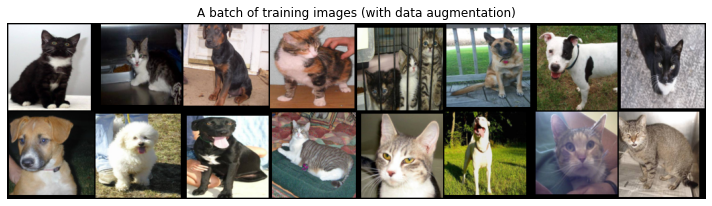

In [5]:
# 从训练生成器取一个 batch 进行展示
images, labels = next(iter(train_loader))
print(f"图片张量形状: {images.shape}")  # [batch_size, 3, 128, 128]
print(f"标签张量形状: {labels.shape}")

plt.figure(figsize=(10, 4))
grid = make_grid(images[:16], nrow=8, normalize=True, value_range=(0, 1))
plt.imshow(grid.permute(1, 2, 0))
plt.title('A batch of training images (with data augmentation)')
plt.axis('off')
plt.tight_layout()
plt.show()

/root/miniconda3/envs/myconda/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 21407 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/root/miniconda3/envs/myconda/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 22270 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/root/miniconda3/envs/myconda/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 20165 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/root/miniconda3/envs/myconda/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 21518 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/root/miniconda3/envs/myconda/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:203: RuntimeWarning: Glyph 21407 missing from current font.
  font.set_text(s, 0, flags=flags)
/root/miniconda3/envs/myconda/lib/python3.7/site-pac

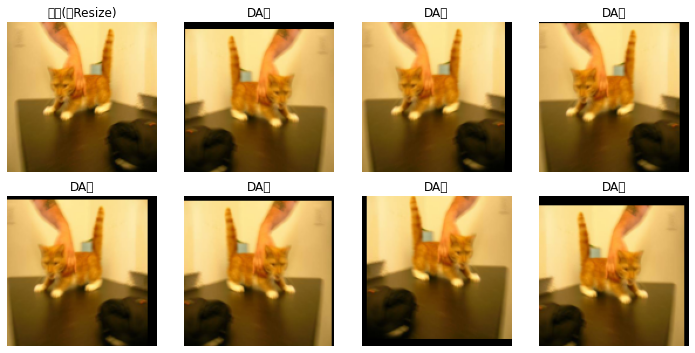

In [6]:
# 直观展示数据增强的效果：同一张图，经过DA后得到不同的"同义"样本
cat_dir = os.path.join(data_dir, 'train', 'cats')
sample_path = os.path.join(cat_dir, sorted(os.listdir(cat_dir))[0])
orig_img = Image.open(sample_path).convert('RGB')

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes[0, 0].imshow(orig_img.resize((IMSIZE, IMSIZE)))
axes[0, 0].set_title('原图(仅Resize)')
for ax in axes.flat[1:]:
    aug = transforms.ToPILImage()(transform_da(orig_img))  # 每次随机裁剪/翻转
    ax.imshow(aug)
    ax.set_title('DA后')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

**分析**：数据集共 25000 张图片，其中训练集 15000 张、验证集 10000 张，猫狗各占 50%，类别平衡。由于数据已按 `类别/图片` 的目录结构组织，使用 `ImageFolder` 可以直接得到 (图片, 标签) 样本对，无需手写 Dataset 类。从数据增强的展示可以看到，同一张猫图经过随机裁剪和水平翻转后生成了多张内容不同但语义相同的"同义"样本，这正是数据增强能够等效扩充训练集、提升泛化能力的原因。

## 2. 模型搭建

### 2.1 自定义CNN（可选BN + kaiming初始化）

网络结构与课件一致，共 3 个卷积块（Conv → BN → ReLU）和 2 次 MaxPool 下采样，最后接全连接层输出 2 类 logits：

- `use_bn=True` 时在每层卷积后插入 `BatchNorm2d`（本次作业对比需要）；
- 权重使用 **kaiming 初始化**：合适的初始化让每层输出的方差保持稳定，避免前向信号衰减/爆炸和反向梯度消失，防止网络"出师未捷身先死"。

In [7]:
class CatDogCNN(nn.Module):
    """猫狗二分类CNN（结构仿课件）。

    参数:
        use_bn: True=卷积层后接BatchNorm2d, False=不接
    输入:  [B, 3, 128, 128]
    输出:  [B, 2] (cat/dog 的 logits)
    """

    def __init__(self, use_bn=True):
        super(CatDogCNN, self).__init__()
        self.use_bn = use_bn

        # ---- 卷积层：Conv -> BN -> ReLU ----
        self.conv1 = nn.Conv2d(3, 16, kernel_size=5, stride=2, padding=0)
        self.bn1 = nn.BatchNorm2d(16) if use_bn else nn.Identity()

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=0)
        self.bn2 = nn.BatchNorm2d(32) if use_bn else nn.Identity()

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=0)
        self.bn3 = nn.BatchNorm2d(64) if use_bn else nn.Identity()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # ---- 全连接层 ----
        self.fc = nn.Sequential(
            nn.Linear(6 * 6 * 64, 128),  # 2304 = 64通道 × 6×6 特征图展平
            nn.ReLU(),
            nn.Dropout(0.5),             # 随机失活，防止过拟合
            nn.Linear(128, 2),           # 2类: cat / dog
        )

        self._initialize_weights()  # 创建模型时立即初始化

    def _initialize_weights(self):
        """kaiming初始化：让每层输出的方差保持稳定，避免梯度消失/爆炸。"""
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_uniform_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))  # [B,16,62,62]
        x = F.relu(self.bn2(self.conv2(x)))  # [B,32,30,30]
        x = self.pool(x)                     # [B,32,15,15]
        x = F.relu(self.bn3(self.conv3(x)))  # [B,64,13,13]
        x = self.pool(x)                     # [B,64,6,6]
        x = torch.flatten(x, 1)              # [B,2304]
        return self.fc(x)                    # [B,2]

### 2.2 实例化四种配置并展示模型summary

作业要求对比的四种配置：

| 配置 | BatchNorm | 数据增强 |
|---|---|---|
| (1) 无BN 无DA | ✗ | ✗ |
| (2) 仅BN | ✓ | ✗ |
| (3) 仅DA | ✗ | ✓ |
| (4) BN+DA | ✓ | ✓ |

其中 BN 由模型的 `use_bn` 开关控制，DA 由训练集的 transform 控制，二者正交，因此可以用同一个模型类完成全部四种对比。

In [8]:
from torchsummary import summary

# 四种实验配置: (名称, 是否使用BN, 是否使用DA)
configs = [
    ('(1) 无BN 无DA', False, False),
    ('(2) 仅BN',      True,  False),
    ('(3) 仅DA',      False, True),
    ('(4) BN+DA',     True,  True),
]

# 展示四种配置的参数量（BN层会带来少量额外参数）
for name, use_bn, use_da in configs:
    set_seed(1)  # 固定种子，保证不同配置的初始权重一致
    model = CatDogCNN(use_bn=use_bn).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name}: 参数量 = {n_params:,}")

print()
print("===== 配置(4) BN+DA 的详细结构 =====")
summary(CatDogCNN(use_bn=True).to(device), (3, IMSIZE, IMSIZE))

(1) 无BN 无DA: 参数量 = 319,650
(2) 仅BN: 参数量 = 319,874
(3) 仅DA: 参数量 = 319,650
(4) BN+DA: 参数量 = 319,874

===== 配置(4) BN+DA 的详细结构 =====
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 62, 62]           1,216
       BatchNorm2d-2           [-1, 16, 62, 62]              32
            Conv2d-3           [-1, 32, 30, 30]           4,640
       BatchNorm2d-4           [-1, 32, 30, 30]              64
         MaxPool2d-5           [-1, 32, 15, 15]               0
            Conv2d-6           [-1, 64, 13, 13]          18,496
       BatchNorm2d-7           [-1, 64, 13, 13]             128
         MaxPool2d-8             [-1, 64, 6, 6]               0
            Linear-9                  [-1, 128]         295,040
             ReLU-10                  [-1, 128]               0
          Dropout-11                  [-1, 128]               0
           Linear-12                  

In [9]:
# 手工核算各层参数量（BN+DA版本），与 summary 的输出互相验证
layer_params = {
    'conv1 (3→16, 5×5)  权重+偏置': 3 * 16 * 5 * 5 + 16,   # 1216
    'bn1  (gamma+beta)': 2 * 16,                            # 32
    'conv2 (16→32, 3×3) 权重+偏置': 16 * 32 * 3 * 3 + 32,  # 4640
    'bn2  (gamma+beta)': 2 * 32,                            # 64
    'conv3 (32→64, 3×3) 权重+偏置': 32 * 64 * 3 * 3 + 64,  # 18496
    'bn3  (gamma+beta)': 2 * 64,                            # 128
    'fc1  (2304→128)    权重+偏置': 2304 * 128 + 128,      # 295040
    'fc2  (128→2)       权重+偏置': 128 * 2 + 2,           # 258
}
for k, v in layer_params.items():
    print(f"{k:35s}: {v:>10,}")
print("-" * 50)
print(f"{'合计':35s}: {sum(layer_params.values()):>10,}")
# BN层占比
bn_params = 2 * 16 + 2 * 32 + 2 * 64
print(f"其中BN层参数占比: {bn_params}/{sum(layer_params.values())} = {bn_params/sum(layer_params.values()):.2%}")
# 全连接层占比
fc_params = layer_params['fc1  (2304→128)    权重+偏置'] + layer_params['fc2  (128→2)       权重+偏置']
print(f"全连接层参数占比: {fc_params}/{sum(layer_params.values())} = {fc_params/sum(layer_params.values()):.2%}")

conv1 (3→16, 5×5)  权重+偏置           :      1,216
bn1  (gamma+beta)                  :         32
conv2 (16→32, 3×3) 权重+偏置           :      4,640
bn2  (gamma+beta)                  :         64
conv3 (32→64, 3×3) 权重+偏置           :     18,496
bn3  (gamma+beta)                  :        128
fc1  (2304→128)    权重+偏置           :    295,040
fc2  (128→2)       权重+偏置           :        258
--------------------------------------------------
合计                                 :    319,874
其中BN层参数占比: 224/319874 = 0.07%
全连接层参数占比: 295298/319874 = 92.32%


**分析（参数数目）**：

- 模型总参数量约 **32万**（BN+DA版本为 319,874），是一个非常轻量的CNN。
- 参数量由"上一层输出 × 下一层输入"决定：例如 `conv1` 参数量 = 输入通道3 × 输出通道16 × 卷积核5×5 + 16个偏置 = 1,216。
- **BN层参数极少**（每个BN只有 2×通道数 的可学习参数 gamma/beta，共224个），不到总参数的0.1%，却显著改变了优化难度。
- **全连接层占绝大部分参数**（295,298，约92%），这是小特征图 + 大 flatten 维度的典型现象；若需要压缩模型，优先考虑削减 fc 层。
- 对比四种配置：无BN版本参数量 = 319,874 − 224 = 319,650，与代码输出一致。

## 3. 模型训练（四种配置对比）

- 损失函数：`CrossEntropyLoss`（分类任务标准损失，内部含 softmax）；
- 优化器：`Adam`，学习率 1e-3；
- 监控指标：训练集 Loss 与验证集 Accuracy，逐 epoch 记录并绘制曲线；
- 四个模型使用**相同的随机种子初始化、相同的 batch 打乱顺序**，保证差异只来自 BN / DA。

In [10]:
criterion = nn.CrossEntropyLoss()


def evaluate(model, loader):
    """在验证集上计算分类精度。"""
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            preds = model(images).argmax(1)
            correct += (preds == labels).sum().item()
            total += labels.numel()
    return correct / total


def train_model(model, train_loader, val_loader, epochs, lr, device):
    """训练并逐 epoch 记录 (训练loss, 验证精度)。"""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train()
        train_loss, n = 0.0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()          # 清空上一轮梯度
            loss = criterion(model(images), labels)
            loss.backward()                # 反向传播
            optimizer.step()               # 更新参数
            train_loss += loss.item() * images.size(0)
            n += images.size(0)
        train_loss /= n
        val_acc = evaluate(model, val_loader)
        history.append((train_loss, val_acc))
        print(f"Epoch [{epoch+1}/{epochs}], train_loss: {train_loss:.4f}, val_acc: {val_acc:.4f}")
    return history

In [11]:
# 依次训练四种配置，保存各自的历史曲线与权重
histories = {}
for idx, (name, use_bn, use_da) in enumerate(configs):
    print(f"\n{'='*20} 训练配置 {name} {'='*20}")
    set_seed(1)  # 每个配置用相同种子：初始权重与batch顺序一致
    _, _, tr_loader, va_loader = build_loaders(use_da)
    model = CatDogCNN(use_bn=use_bn).to(device)
    histories[name] = train_model(model, tr_loader, va_loader, epochs, lr, device)
    torch.save(model.state_dict(), f"hw5_model_{idx}.pth")  # 供后续推断使用
    print(f"配置 {name} 训练完成，最终验证精度: {histories[name][-1][1]:.4f}")


==================== 训练配置 (1) 无BN 无DA ====================
Epoch [1/30], train_loss: 0.6663, val_acc: 0.6254
Epoch [2/30], train_loss: 0.5893, val_acc: 0.7141
Epoch [3/30], train_loss: 0.5310, val_acc: 0.7612
Epoch [4/30], train_loss: 0.4864, val_acc: 0.7602
Epoch [5/30], train_loss: 0.4466, val_acc: 0.7867
Epoch [6/30], train_loss: 0.4199, val_acc: 0.7831
Epoch [7/30], train_loss: 0.3856, val_acc: 0.7948
Epoch [8/30], train_loss: 0.3635, val_acc: 0.8099
Epoch [9/30], train_loss: 0.3250, val_acc: 0.8159
Epoch [10/30], train_loss: 0.2983, val_acc: 0.8200
Epoch [11/30], train_loss: 0.2705, val_acc: 0.8221
Epoch [12/30], train_loss: 0.2673, val_acc: 0.8161
Epoch [13/30], train_loss: 0.2181, val_acc: 0.8097
Epoch [14/30], train_loss: 0.2014, val_acc: 0.8189
Epoch [15/30], train_loss: 0.1737, val_acc: 0.8178
Epoch [16/30], train_loss: 0.1618, val_acc: 0.8080
Epoch [17/30], train_loss: 0.1411, val_acc: 0.8166
Epoch [18/30], train_loss: 0.1253, val_acc: 0.8053
Epoch [19/30], train_loss: 0.10

### 3.1 训练集 Loss 曲线与验证集 Accuracy 曲线对比

/root/miniconda3/envs/myconda/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 26080 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/root/miniconda3/envs/myconda/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:203: RuntimeWarning: Glyph 26080 missing from current font.
  font.set_text(s, 0, flags=flags)


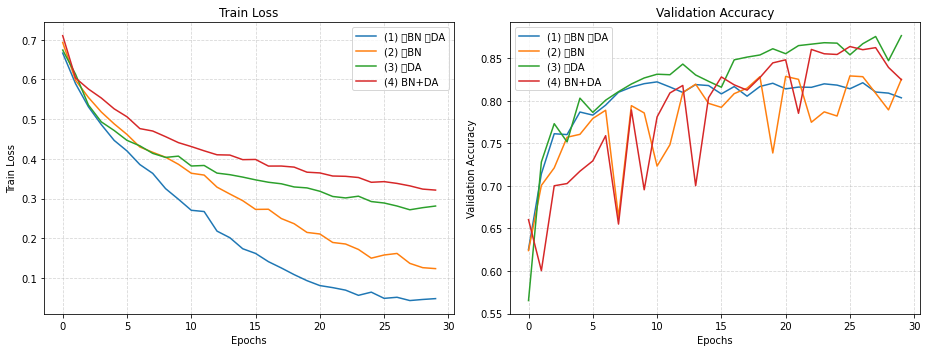

In [12]:
plt.figure(figsize=(13, 5))

# 左图: 训练集 Loss
plt.subplot(1, 2, 1)
for name, hist in histories.items():
    plt.plot([h[0] for h in hist], label=name)
plt.xlabel('Epochs')
plt.ylabel('Train Loss')
plt.title('Train Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 右图: 验证集 Accuracy
plt.subplot(1, 2, 2)
for name, hist in histories.items():
    plt.plot([h[1] for h in hist], label=name)
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**分析（训练曲线）**：四种配置各训练 30 个 epoch，最终验证精度：(1) 80.34% (2) 82.51% (3) 87.64% (4) 82.47%。

1. **BN 的作用（对比(1)与(2)）**：仅BN比基线高 2.17pp（82.51% vs 80.34%），主要改善体现在**训练后期的稳定性**——配置(1)在 epoch 11 达到峰值 82.21% 后持续回落，最终掉了 1.87pp；而配置(2)的峰值出现在 epoch 26（82.91%），最终仅比峰值低 0.40pp。BN 通过归一化中间特征、缓解内部协变量偏移，抑制了训练后期的震荡，但两者的收敛速度接近（epoch 5 时 76.05% vs 78.67%）。

2. **DA 的作用（对比(1)与(3)）**：数据增强是四种因素中**提升最大**的，+7.30pp（87.64% vs 80.34%）。配置(3)的验证精度峰值恰好出现在最后一个 epoch（87.64%@ep30），训练 loss 仍有 0.281——30 个 epoch 内模型一直在学习可泛化的特征，而没有去死记训练集；反观配置(1)，训练 loss 已降到 0.048（基本背下训练集），验证精度却不升反降。DA 的代价是初期拟合更慢（epoch 1 仅 56.53%，为四者最低），但 epoch 5 时已反超基线（80.30% > 78.67%），随后持续领先。

3. **BN+DA 未产生叠加收益的意外现象（对比(3)与(4)）**：理论上正交互补的二者组合（82.47%）却与仅BN（82.51%）基本持平，明显低于仅DA（87.64%）。细看曲线：配置(4)在 epoch 26 曾达到 86.36%，但后期大幅回落 3.89pp，是四种配置中**回落最大**的，说明该组合训练后期波动剧烈。可能的原因：(a) 单次实验的随机性——只用一个种子，5pp 的差距不能完全排除噪声，严谨做法是多个种子重复取均值；(b) BN 的 batch 统计量在增强数据上波动更大，再叠加 Dropout(0.5) 的随机失活，两种随机性互相干扰；(c) BN 训练时用 batch 均值/方差、推理时用滑动平均，与 Dropout 共同作用会放大训练-推理行为的不一致。

4. **结论**：在本实验设置下，**数据增强是提升泛化能力最有效的手段**，BN 次之；BN+DA 的组合未表现出预期的叠加收益，其回落现象值得用多种子实验进一步验证。

## 4. 测试集精度与模型精度得分

作业评分规则：模型在测试集（本作业取验证集）上的分类精度为 x%，精度得分 = 20 × x / 100。

In [13]:
# 汇总四种配置的最终验证精度
print("===== 四种配置的最终验证精度 =====")
final_accs = {name: hist[-1][1] for name, hist in histories.items()}
for name, acc in final_accs.items():
    print(f"{name}: {acc*100:.2f}%")

# 最佳配置及其得分
best_name = max(final_accs, key=final_accs.get)
x = final_accs[best_name] * 100
print(f"\n最佳配置: {best_name}")
print(f"测试集精度 x = {x:.2f}%")
print(f"模型精度得分 = 20 * x / 100 = {20 * x / 100:.2f}")

===== 四种配置的最终验证精度 =====
(1) 无BN 无DA: 80.34%
(2) 仅BN: 82.51%
(3) 仅DA: 87.64%
(4) BN+DA: 82.47%

最佳配置: (3) 仅DA
测试集精度 x = 87.64%
模型精度得分 = 20 * x / 100 = 17.53


## 5. 模型推断

用表现最好的配置对应的模型，从验证集随机取 5 张图片进行推断，输出每张图片的预测类别与概率（softmax 后取最大值的置信度）。

已载入最佳模型: 配置 (3) 仅DA


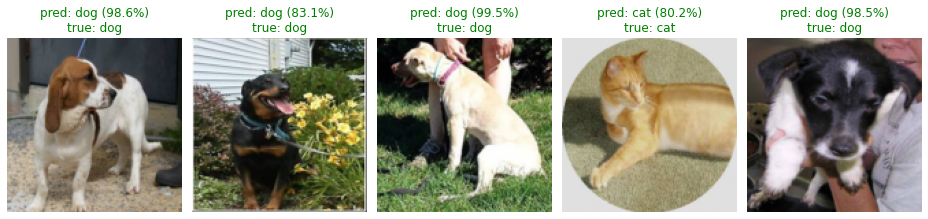

===== 推断结果（含两类概率）=====
图1: 真实=dog  预测=dog  概率=[cat 0.014, dog 0.986] ✓
图2: 真实=dog  预测=dog  概率=[cat 0.169, dog 0.831] ✓
图3: 真实=dog  预测=dog  概率=[cat 0.005, dog 0.995] ✓
图4: 真实=cat  预测=cat  概率=[cat 0.802, dog 0.198] ✓
图5: 真实=dog  预测=dog  概率=[cat 0.015, dog 0.985] ✓


In [14]:
# 载入最佳配置对应的模型权重
best_idx = [i for i, (name, _, _) in enumerate(configs) if name == best_name][0]
_, best_bn, best_da = configs[best_idx]

best_model = CatDogCNN(use_bn=best_bn).to(device)
best_model.load_state_dict(torch.load(f"hw5_model_{best_idx}.pth", map_location=device))
best_model.eval()
print(f"已载入最佳模型: 配置 {best_name}")

# 从验证集随机抽取5张图片（注意：用与评估一致的 transform_val，不做增强）
infer_set = torchvision.datasets.ImageFolder(
    root=os.path.join(data_dir, 'validation'), transform=transform_val)
infer_loader = torch.utils.data.DataLoader(
    infer_set, batch_size=5, shuffle=True, generator=torch.Generator().manual_seed(42))
images, labels = next(iter(infer_loader))

with torch.no_grad():
    probs = F.softmax(best_model(images.to(device)), dim=1)  # 归一化为概率
preds = probs.argmax(1)

# 展示图片 + 预测结果 + 概率
plt.figure(figsize=(13, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i].permute(1, 2, 0).numpy())
    pred_name = class_names[preds[i]]
    true_name = class_names[labels[i]]
    confidence = probs[i].max().item()
    color = 'green' if preds[i] == labels[i] else 'red'
    plt.title(f"pred: {pred_name} ({confidence:.1%})\ntrue: {true_name}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

print("===== 推断结果（含两类概率）=====")
for i in range(5):
    print(f"图{i+1}: 真实={class_names[labels[i]]:4s} 预测={class_names[preds[i]]:4s} "
          f"概率=[cat {probs[i,0]:.3f}, dog {probs[i,1]:.3f}] "
          f"{'✓' if preds[i]==labels[i] else '✗'}")

**分析（推断结果）**：使用最佳配置 (3) 仅DA 训练出的模型，对验证集随机抽取的 5 张图片进行推断，**5 张全部预测正确**。其中 4 张置信度高于 83%（如"图3"判为 dog 的概率高达 0.995），模型判断非常确定；"图4"（真实为 cat）的置信度相对较低（cat 概率 0.802），说明该图中猫的体态或背景使模型略有犹豫，但最终仍给出了正确判断。整体来看，模型输出的置信度与 87.64% 的验证精度相一致，预测结果直观可解释。

## 6. 总结

本次作业在猫狗数据集（15000训练 + 10000验证）上，用同一个自定义CNN（319,874 参数，kaiming初始化）系统对比了 BatchNorm 与数据增强四种组合：

1. **数据读取**：`ImageFolder` 按目录结构自动构造带标签数据集；DA 通过随机裁剪+水平翻转制造"同义"样本，验证集不做增强。
2. **模型搭建**：3×(Conv-BN-ReLU) + 2×MaxPool + FC(2304→128→2)；`use_bn` 开关控制 BN，参数量手工核算（319,874）与 torchsummary 输出一致。
3. **训练对比**（各30 epochs，相同随机种子）：

| 配置 | 峰值验证精度 | 最终验证精度 |
|---|---|---|
| (1) 无BN 无DA | 82.21% (@ep11) | 80.34% |
| (2) 仅BN | 82.91% (@ep26) | 82.51% |
| (3) 仅DA | 87.64% (@ep30) | **87.64%** |
| (4) BN+DA | 86.36% (@ep26) | 82.47% |

4. **主要发现**：DA 提升最大（+7.30pp），且完全消除了训练后期的过拟合回落；BN 提升 2.17pp，主要改善训练后期稳定性；BN+DA 未产生叠加收益，后期回落最大（3.89pp），可能与单种子随机性、BN统计量与Dropout随机性叠加有关。
5. **推断**：最佳模型在验证集抽样的 5 张图片上全部预测正确，置信度与验证精度一致。

**模型精度得分**：最佳配置为 (3) 仅DA，测试集精度 x = 87.64%，得分 = 20 × 87.64 / 100 = **17.53 / 20**。